# Task 05 – Time-Series Forecasting with ARIMA

**Objective:** Analyze daily demand, inspect trend and weekly seasonality, test stationarity, train an ARIMA model, evaluate it with RMSE and MAPE, and generate a 30-day forecast.

## Dataset
The supplied dataset contains 30 daily observations and the columns:
- `date`: observation date
- `demand`: daily demand (forecast target)
- `marketing_event`: indicator feature
- `holiday`: indicator feature

> Note: The dataset is short (30 observations). Forecasts beyond the observed period should be treated as exploratory, not as highly reliable long-term predictions. This notebook uses univariate ARIMA, so the event and holiday columns are inspected but are not model inputs.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

In [2]:
# Run this notebook from the notebooks/ folder.
DATA_PATH = "../data/daily-demand-series.csv"

df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date").asfreq("D")

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (30, 3)


,demand,marketing_event,holiday
date,,,
2026-06-01,118,0,0
2026-06-02,121,0,0
2026-06-03,125,0,0
2026-06-04,123,0,0
2026-06-05,137,1,0


<class 'pandas.DataFrame'>
DatetimeIndex: 30 entries, 2026-06-01 to 2026-06-30
Freq: D
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   demand           30 non-null     int64
 1   marketing_event  30 non-null     int64
 2   holiday          30 non-null     int64
dtypes: int64(3)
memory usage: 960.0 bytes


None

## 3. Inspect and clean the data

In [3]:
print("Missing values before handling:")
display(df.isna().sum())

print("Duplicate dates:", df.index.duplicated().sum())

# Interpolate missing numeric values if any are introduced by the daily frequency.
df["demand"] = df["demand"].interpolate(method="time")
for col in ["marketing_event", "holiday"]:
    if col in df.columns:
        df[col] = df[col].fillna(0)

print("\nMissing values after handling:")
display(df.isna().sum())
display(df.describe(include="all"))

Missing values before handling:


demand             0
marketing_event    0
holiday            0
dtype: int64

Duplicate dates: 0

Missing values after handling:


demand             0
marketing_event    0
holiday            0
dtype: int64

,demand,marketing_event,holiday
count,30.000000,30.000000,30.000000
mean,142.100000,0.266667,0.133333
std,13.839848,0.449776,0.345746
min,118.000000,0.000000,0.000000
25%,132.500000,0.000000,0.000000
50%,142.000000,0.000000,0.000000
75%,150.250000,0.750000,0.000000
max,174.000000,1.000000,1.000000


## 4. Exploratory data analysis

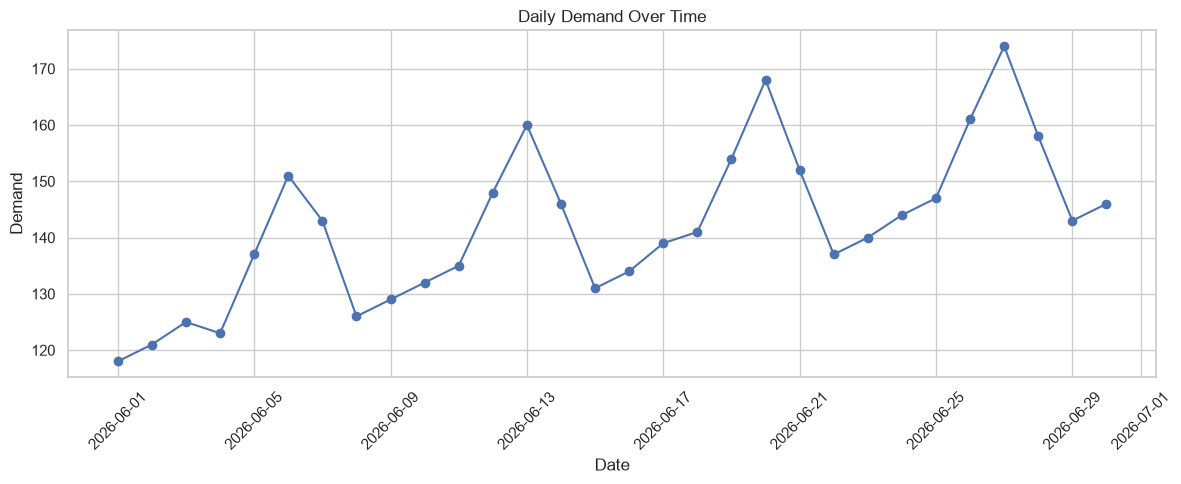

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df.index, df["demand"], marker="o")
ax.set_title("Daily Demand Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

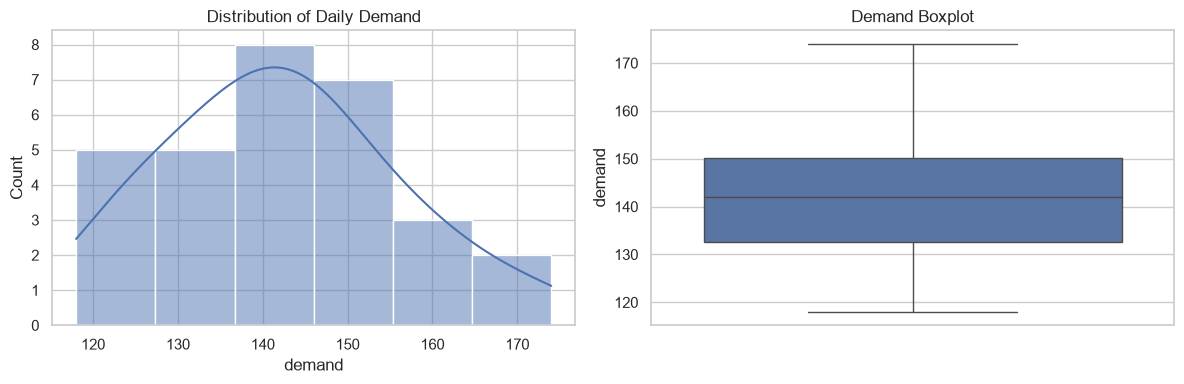

Marketing-event days: 8
Holiday days: 4


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["demand"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of Daily Demand")
sns.boxplot(y=df["demand"], ax=axes[1])
axes[1].set_title("Demand Boxplot")
plt.tight_layout()
plt.show()

print("Marketing-event days:", int(df["marketing_event"].sum()))
print("Holiday days:", int(df["holiday"].sum()))

## 5. Time-series decomposition

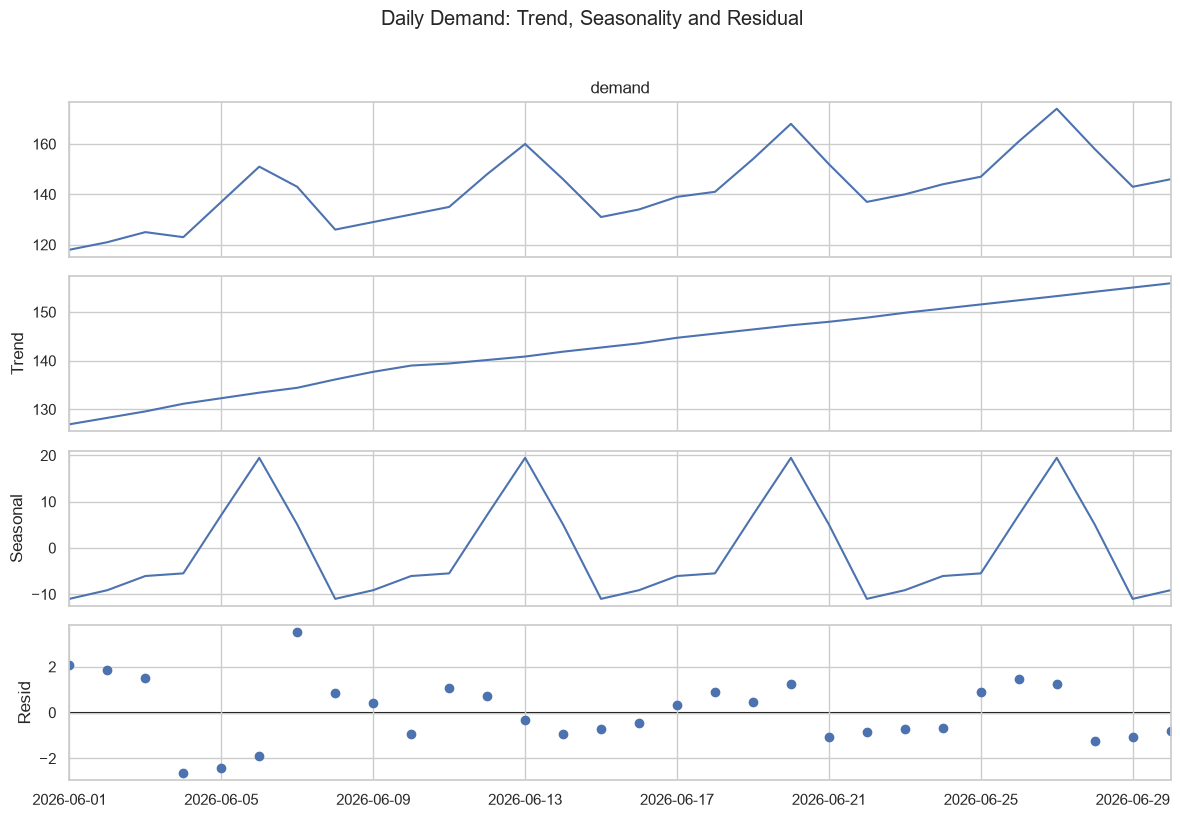

In [6]:
# A period of 7 checks for a weekly pattern.
decomposition = seasonal_decompose(
    df["demand"],
    model="additive",
    period=7,
    extrapolate_trend="freq"
)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Daily Demand: Trend, Seasonality and Residual", y=1.02)
plt.tight_layout()
plt.show()

## 6. Augmented Dickey-Fuller (ADF) stationarity test

In [7]:
def run_adf(series, label):
    result = adfuller(series.dropna(), autolag="AIC")
    print(f"{label}")
    print(f"ADF statistic: {result[0]:.4f}")
    print(f"p-value:       {result[1]:.4f}")
    print("Conclusion:", "Stationary (reject H0)" if result[1] < 0.05
          else "Non-stationary (fail to reject H0)")
    print("")

run_adf(df["demand"], "ADF test on original demand")

ADF test on original demand
ADF statistic: -0.9039
p-value:       0.7867
Conclusion: Non-stationary (fail to reject H0)



## 7. First-order differencing and stationarity check

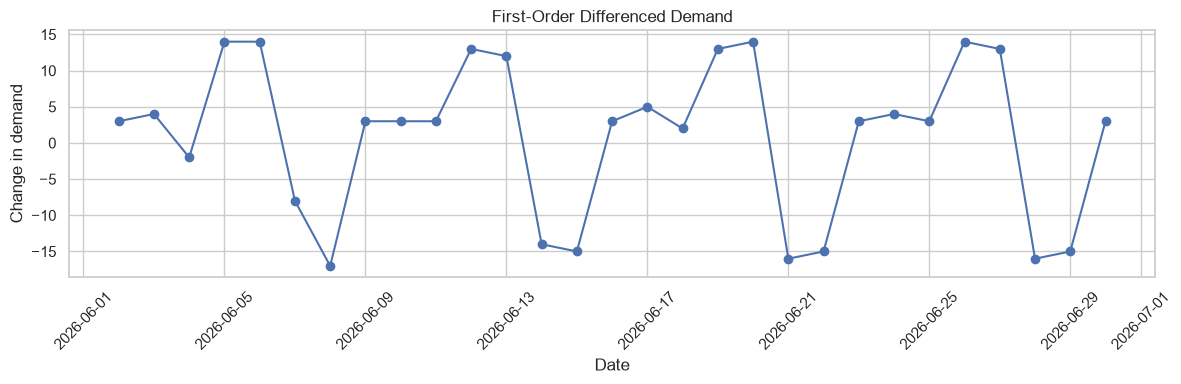

ADF test after first-order differencing
ADF statistic: -2.2336
p-value:       0.1943
Conclusion: Non-stationary (fail to reject H0)



In [8]:
demand_diff = df["demand"].diff().dropna()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(demand_diff.index, demand_diff, marker="o")
ax.set_title("First-Order Differenced Demand")
ax.set_xlabel("Date")
ax.set_ylabel("Change in demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

run_adf(demand_diff, "ADF test after first-order differencing")

## 8. Train-test split

The final 7 observations are held out for testing. The earlier observations are used to train the model. Because this dataset has only 30 rows, the test metrics may vary substantially with a different split.

In [9]:
test_size = 7
train = df["demand"].iloc[:-test_size]
test = df["demand"].iloc[-test_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training period:", train.index.min().date(), "to", train.index.max().date())
print("Testing period:", test.index.min().date(), "to", test.index.max().date())

Training observations: 23
Testing observations: 7
Training period: 2026-06-01 to 2026-06-23
Testing period: 2026-06-24 to 2026-06-30


## 9. Select an ARIMA order using AIC

In [10]:
candidate_orders = [
    (0, 1, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2),
    (2, 1, 1),
]

results = []
for order in candidate_orders:
    try:
        fitted = ARIMA(train, order=order).fit()
        results.append({"order": order, "AIC": fitted.aic})
    except Exception as exc:
        print(f"Could not fit ARIMA{order}: {exc}")

aic_table = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
display(aic_table)

if aic_table.empty:
    raise RuntimeError("None of the candidate ARIMA models could be fitted.")

best_order = aic_table.loc[0, "order"]
print("Selected ARIMA order:", best_order)

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,order,AIC
0,"(0, 1, 2)",161.222468
1,"(2, 1, 1)",161.414090
2,"(2, 1, 0)",161.729235
3,"(0, 1, 1)",162.584534
4,"(1, 1, 1)",164.240391
5,"(0, 1, 0)",167.916471
6,"(1, 1, 0)",168.761754


Selected ARIMA order: (0, 1, 2)


## 10. Fit the selected ARIMA model

In [11]:
arima_model = ARIMA(train, order=best_order)
arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                 demand   No. Observations:                   23
Model:                 ARIMA(0, 1, 2)   Log Likelihood                 -77.611
Date:                Fri, 20 Nov 2026   AIC                            161.222
Time:                        19:26:51   BIC                            164.496
Sample:                    06-01-2026   HQIC                           161.994
                         - 06-23-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.1614      0.185      0.872      0.383      -0.201       0.524
ma.L2         -0.7148      0.233     -3.070      0.002      -1.171      -0.258
sigma2        62.5816     23.835      2.626      0.0

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


## 11. Forecast the test period

In [12]:
test_forecast = arima_fit.forecast(steps=len(test))
test_forecast.index = test.index

comparison = pd.DataFrame({
    "Actual": test,
    "Predicted": test_forecast
})
display(comparison)

,Actual,Predicted
date,,
2026-06-24,144,144.118782
2026-06-25,147,144.776906
2026-06-26,161,144.776906
2026-06-27,174,144.776906
2026-06-28,158,144.776906
2026-06-29,143,144.776906
2026-06-30,146,144.776906


## 12. Evaluate the model using RMSE and MAPE

In [13]:
rmse = np.sqrt(mean_squared_error(test, test_forecast))

# MAPE is undefined when actual values contain zero.
if (test == 0).any():
    mape = np.nan
    print("MAPE not calculated because the test set contains zero actual values.")
else:
    mape = mean_absolute_percentage_error(test, test_forecast) * 100

print(f"RMSE: {rmse:.3f}")
print("MAPE:", f"{mape:.2f}%" if pd.notna(mape) else "Not available")

RMSE: 13.636
MAPE: 5.56%


## 13. Plot actual versus predicted demand

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Training demand")
plt.plot(test.index, test, marker="o", label="Actual test demand")
plt.plot(test_forecast.index, test_forecast, marker="x", label="ARIMA forecast")
plt.title(f"Actual vs Predicted Demand – ARIMA{best_order}")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 14. Refit on all observations and forecast the next 30 days

In [ ]:
final_fit = ARIMA(df["demand"], order=best_order).fit()
future_result = final_fit.get_forecast(steps=30)

future_dates = pd.date_range(
    start=df.index[-1] + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

future_mean = pd.Series(future_result.predicted_mean.to_numpy(), index=future_dates)
future_ci = future_result.conf_int()
future_ci.index = future_dates

forecast_df = pd.DataFrame({
    "date": future_dates,
    "forecasted_demand": future_mean.to_numpy(),
    "lower_bound": future_ci.iloc[:, 0].to_numpy(),
    "upper_bound": future_ci.iloc[:, 1].to_numpy()
})

display(forecast_df)

## 15. Visualize the 30-day forecast with confidence intervals

In [ ]:
plt.figure(figsize=(13, 6))
plt.plot(df.index, df["demand"], label="Historical demand")
plt.plot(future_dates, future_mean, color="tab:red", label="30-day forecast")
plt.fill_between(
    future_dates,
    future_ci.iloc[:, 0].to_numpy(),
    future_ci.iloc[:, 1].to_numpy(),
    alpha=0.2,
    label="95% confidence interval"
)
plt.title("30-Day Daily Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 16. Save forecast output

In [ ]:
OUTPUT_PATH = "../data/30_day_demand_forecast.csv"
forecast_df.to_csv(OUTPUT_PATH, index=False)
print(f"Forecast saved to: {OUTPUT_PATH}")

## 17. Conclusion

This notebook explored the daily demand series, decomposed it into trend/seasonal/residual components, checked stationarity using the ADF test, applied first-order differencing, selected an ARIMA model using AIC, and evaluated its held-out predictions using RMSE and MAPE. It then refitted the selected model on all available observations and generated a 30-day forecast with confidence intervals.

**Interpretation reminder:** Only 30 daily observations are available. A longer history is recommended to estimate seasonality and validate future forecasts more reliably. The `marketing_event` and `holiday` variables were not included in this univariate ARIMA model; a future extension could test an ARIMAX/SARIMAX model using these explanatory variables.